# CENG 463 – HW3: CIFAR-10 Image Clustering
**Due Date:** 05.01.2026

As an **image clustering task**, you will work with the CIFAR-10 dataset, which contains images from 10 classes, including airplanes, cars, cats, and dogs. The goal is to use **unsupervised learning** techniques to group similar images automatically and visualize the results.

## 1. Dataset Overview (10 pts)
- Load the dataset using Keras (More information: [Keras CIFAR-10.](https://keras.io/api/datasets/cifar10/)):

    from keras.datasets import cifar10

   (x_train, y_train), (x_test, y_test) = cifar10.load_data()

- Show the dataset size and class names in a table.
- Display sample images from each class.


/home/mmertince/Documents/GitHub/CENG463_HW_IMG_CLUSTERING/.venv/lib64/python3.13/site-packages/keras/src/datasets/cifar.py:18: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  d = cPickle.load(f, encoding="bytes")


/home/mmertince/Documents/GitHub/CENG463_HW_IMG_CLUSTERING/.venv/lib64/python3.13/site-packages/keras/src/datasets/cifar.py:18: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  d = cPickle.load(f, encoding="bytes")



------------------------------------------------------------
CIFAR-10 Dataset Summary
------------------------------------------------------------

Training set shape: (50000, 32, 32, 3)
Training labels shape: (50000, 1)
Test set shape: (10000, 32, 32, 3)
Test labels shape: (10000, 1)

------------------------------
 Dataset  Num Samples Image Shape  Num Classes
Training        50000     32×32×3           10
    Test        10000     32×32×3           10
   Total        60000     32×32×3           10

------------------------------------------------------------
Class Names:
------------------------------------------------------------
 Class Index Class Name
           0   Airplane
           1 Automobile
           2       Bird
           3        Cat
           4       Deer
           5        Dog
           6       Frog
           7      Horse
           8       Ship
           9      Truck


/home/mmertince/Documents/GitHub/CENG463_HW_IMG_CLUSTERING/.venv/lib64/python3.13/site-packages/keras/src/datasets/cifar.py:18: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  d = cPickle.load(f, encoding="bytes")



------------------------------------------------------------
CIFAR-10 Dataset Summary
------------------------------------------------------------

Training set shape: (50000, 32, 32, 3)
Training labels shape: (50000, 1)
Test set shape: (10000, 32, 32, 3)
Test labels shape: (10000, 1)

------------------------------
 Dataset  Num Samples Image Shape  Num Classes
Training        50000     32×32×3           10
    Test        10000     32×32×3           10
   Total        60000     32×32×3           10

------------------------------------------------------------
Class Names:
------------------------------------------------------------
 Class Index Class Name
           0   Airplane
           1 Automobile
           2       Bird
           3        Cat
           4       Deer
           5        Dog
           6       Frog
           7      Horse
           8       Ship
           9      Truck


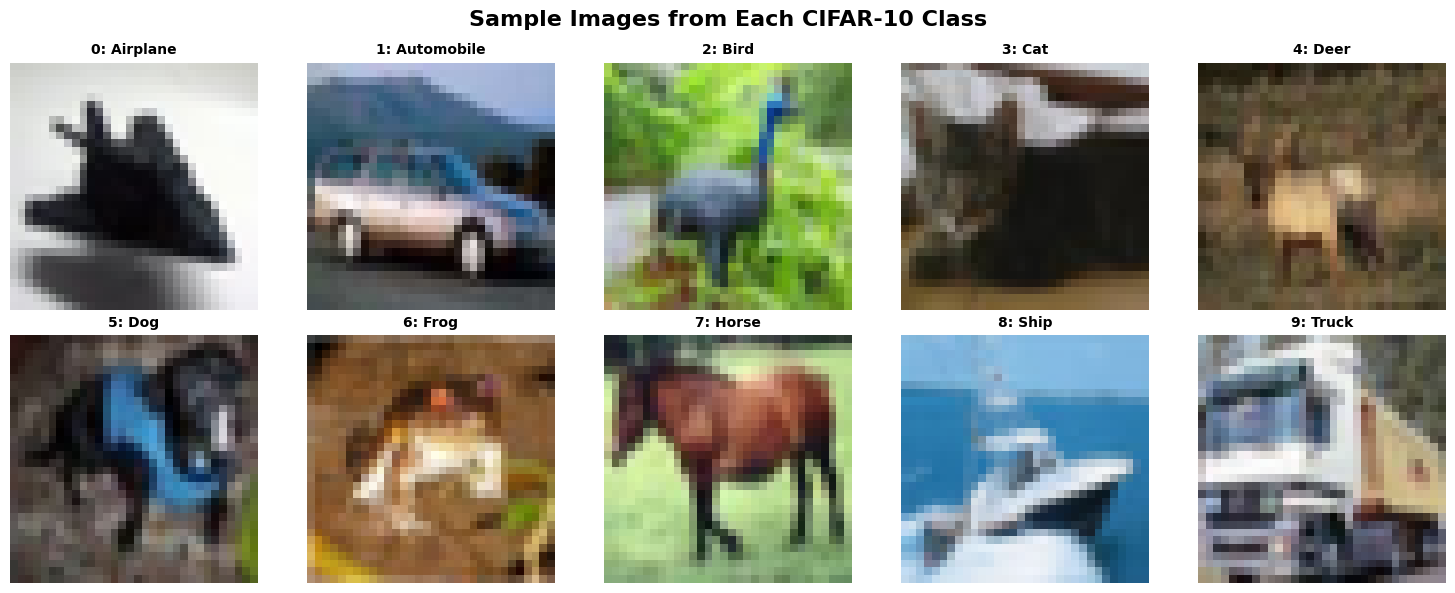


------------------------------------------------------------
Dataset loaded successfully!


In [5]:
#Dataset Overview

import keras
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

#loading the dataset
(x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()

#CIFAR-10 dataset class names
class_names = ['Airplane', 'Automobile', 'Bird', 'Cat', 'Deer', 'Dog', 'Frog', 'Horse', 'Ship', 'Truck']

#displaying dataset size 
print("\n" + "-" * 60)
print("CIFAR-10 Dataset Summary")
print("-" * 60)
print(f"\nTraining set shape: {x_train.shape}")
print(f"Training labels shape: {y_train.shape}")
print(f"Test set shape: {x_test.shape}")
print(f"Test labels shape: {y_test.shape}")

#pandas dataframe for dataset summary
dataset_summary = pd.DataFrame({
    'Dataset': ['Training', 'Test', 'Total'],
    'Num Samples': [len(x_train), len(x_test), len(x_train) + len(x_test)],
    'Image Shape': ['32×32×3', '32×32×3', '32×32×3'], #32x32 images with 3 color channels(RGB)
    'Num Classes': [10, 10, 10]
})

print("\n" +"-" * 30)
print(dataset_summary.to_string(index=False))

#displaying class names

#pandas dataframe for class names
class_table = pd.DataFrame({
    'Class Index': range(10),
    'Class Name': class_names
})

print("\n" + "-" * 60)
print("Class Names")
print("-" * 60)
print(class_table.to_string(index=False))

#displayin sample images from each class
fig, axes = plt.subplots(2, 5, figsize=(15, 6)) #2 rows, 5 columns
fig.suptitle('Sample Images from Each CIFAR-10 Class', fontsize=16, fontweight='bold')

first_img_per_class = []

for i in range(10):
    #finding an image from each class
    class_i_samples = np.where(y_train == i)[0] #class i samples for class i(0 -> 'Airplane', 1 -> 'Automobile', ...)
    sample_idx = class_i_samples[0] #taking the first image from the class
    first_img_per_class.append(x_train[sample_idx])
    
    ax = axes[i // 5, i % 5] #positioning the subplot
    ax.imshow(first_img_per_class[i]) #displaying the image
    ax.set_title(f'{i}: {class_names[i]}', fontsize=10, fontweight='bold') #setting title
    ax.axis('off') #turning off axis

plt.tight_layout()
plt.show()

print("\n"  +"-" * 60)
print("Dataset loaded successfully!")

## 2. Feature Extraction and PCA (30 pts)
- Convert each image from 32×32×3 into a 3072-dimensional vector.
- Scale the vectors using StandardScaler.
- Apply PCA to reduce the dimensionality from 3072 → 50.

In [61]:
#Feature Extraction and PCA 

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

#converting each image from 32×32×3 into a 3072-dimensional vector.
flattened_images = x_train.reshape(x_train.shape[0], -1)

#printing the shape of the converted vectors
print("\n" + "-" * 60)
print(f"Each image converted to vector of shape: {flattened_images[0].shape[0]}")
print("-" * 60)

#scale the vectors using StandardScaler
scaler = StandardScaler() #initializing the scaler
scaled_images = scaler.fit_transform(flattened_images.reshape(-1, 3072))
print("\n" + "-" * 60) 
print (f"Scaled image vectors shape: {scaled_images[0].shape[0]}")
print("-" * 60)

#apply PCA to reduce the dimensionality from 3072 to 50

pca = PCA(n_components=50)
pca.fit(scaled_images)
pca_images = pca.transform(scaled_images)


print("\n" + "-" * 60) 
print(f"Dimensionality reduced to: {pca_images.shape[1]} using PCA")
print("-" * 60)



## 3. Clustering Methods (30 pts)
- Perform clustering on the PCA-transformed features using three Sklearn algorithms: K-Means, Agglomerative Clustering, DBSCAN.
- Visualize example images for each cluster.
- Provide short comments on the clusters.

In [ ]:
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN

#Perform clustering on the PCA-transformed features using K-Means
kmeans = KMeans(n_clusters=10, random_state=42) #10 clusters for 10 classes
kmeans.fit(pca_images) #fit pca reduced images to kmeans


Clustering Methods

1. K-Means Clustering
------------------------------------------------------------
K-Means completed. 10 clusters found.

2. Agglomerative Clustering
------------------------------------------------------------


## 4. Visualization and Analysis (30 pts)
- Use t-SNE to reduce PCA features to 2D for visualization.
- Create colored scatter plots for each clustering algorithm.
- Observe which classes are better grouped by each algorithm.

In [ ]:
# TO DO